In [14]:
%%javascript

IPython.tab_as_tab_everywhere = function(use_tabs) {
    if (use_tabs === undefined) {
        use_tabs = true; 
    }

    // apply setting to all current CodeMirror instances
    IPython.notebook.get_cells().map(
        function(c) {  return c.code_mirror.options.indentWithTabs=use_tabs;  }
    );
    // make sure new CodeMirror instances created in the future also use this setting
    CodeMirror.defaults.indentWithTabs=use_tabs;

    };

IPython.tab_as_tab_everywhere()

<IPython.core.display.Javascript object>

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

import geopandas as gpd
from geovoronoi import  coords_to_points, voronoi_regions_from_coords

from utils.chrono import Chrono
import glob
import pickle
import seaborn as sns

from matplotlib import rcParams
rcParams.update({'figure.autolayout': True})

from sklearn.ensemble import IsolationForest #1
from sklearn.cluster import DBSCAN #2

from scipy.spatial import Delaunay

def defaultPlotting():
	sns.set_context("talk")
	#sns.set(rc={"font.size":20,"axes.titlesize":20,"axes.labelsize":20})#'figure.figsize':(11.7,8.27),
	
defaultPlotting()

do_pickle = False

# GIS Senegal

In [ ]:
files = glob.glob('/d4d/senegal/SET2/SET*.CSV')

print("Num. file: ", len(files))

if do_pickle:
	j=0
	for fl in files:
		user_data = pd.read_csv(fl)

		with open('senegal_data_' + str(j) + '.pickle', 'wb') as handle:
			pickle.dump(user_data, handle, protocol=pickle.HIGHEST_PROTOCOL)
		j=j+1
else:
	user_data=[]
	for j in range(len(files)):
		with open('senegal_data_' + str(j) + '.pickle', 'rb') as handle:
			user_data.append( pickle.load(handle) )

Num. file:  0


In [ ]:
with open('/SenegalData/senegal_antennas.pickle', 'rb') as handle:
	antennas = pickle.load(handle)

print("{} antennas".format(len(antennas)), antennas['geometry'])


1666 antennas 0       POINT (227957.216 1631771.539)
1       POINT (228042.205 1631837.233)
2       POINT (228231.611 1631587.559)
3       POINT (228899.037 1631749.691)
4       POINT (229271.581 1631073.297)
                     ...              
1661    POINT (885392.807 1401853.817)
1662    POINT (884977.244 1446658.873)
1663    POINT (886293.414 1419278.558)
1664    POINT (886684.756 1391731.765)
1665    POINT (894175.540 1380637.047)
Name: geometry, Length: 1666, dtype: geometry


## GIS viz
* Antennas are points
* Computing Voronoi tesselation
* Set geopandas's country borders as a limit for the tesselation

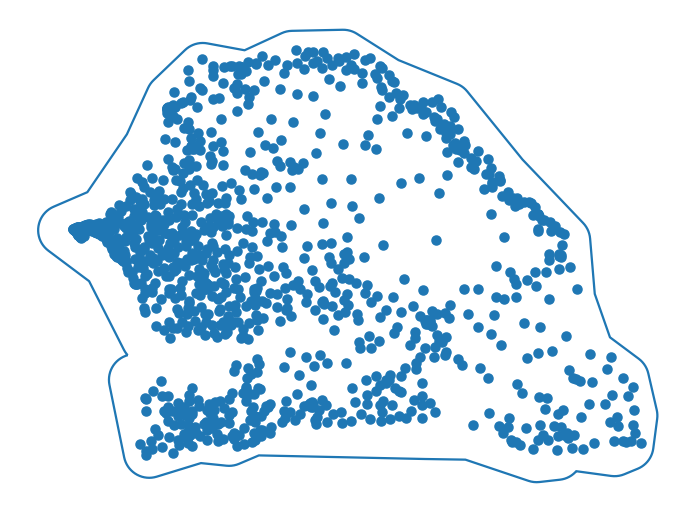

In [20]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres')).to_crs('epsg:31028')
sen_geom_df = world[world['iso_a3']=='SEN'].buffer(30000)
sen_geom = sen_geom_df.iloc[0]

fig, ax = plt.subplots(figsize=(10,10))
antennas.plot(ax=ax)
sen_geom_df.boundary.plot(ax=ax)
ax.axis(False)
plt.show()

In [21]:
#pts_filtered = [p for p in coords_to_points(np.array([antennas.x, antennas.y]).T) if p.within(sen_geom)]

#print(pts_filtered, antennas.x)

# Voronoying stuff
poly_shapes, pts = voronoi_regions_from_coords(np.array([antennas.x, antennas.y]).T,
                                               sen_geom)

# Parsing into a nice dataframe. pts[k][0] is the row nb, not the antenna id
voronoi_map = gpd.GeoDataFrame([[pts[k][0], poly_shapes[k]] for k in poly_shapes.keys()],
                               columns=['site_id', 'geometry']).set_crs('epsg:31028').sort_values('site_id').reset_index(drop=True)

# finding the true antenna id of each row
voronoi_map = voronoi_map.merge(antennas[['site_id']], left_on='site_id', right_index=True, suffixes=('_tmp', ''))

print(voronoi_map)

      site_id_tmp                                           geometry  site_id
0               0  POLYGON ((228095.246 1631680.791, 224900.736 1...        1
1               1  POLYGON ((227989.991 1637013.489, 228505.120 1...        2
2               2  POLYGON ((227816.356 1629681.519, 224900.736 1...        3
3               3  POLYGON ((228489.681 1631980.013, 228681.778 1...        4
4               4  POLYGON ((228216.370 1630248.062, 228681.778 1...        5
...           ...                                                ...      ...
1661         1661  POLYGON ((910828.840 1399956.922, 876945.905 1...     1665
1662         1662  POLYGON ((874093.350 1445620.449, 897416.363 1...     1664
1663         1663  POLYGON ((877554.362 1410994.596, 872706.736 1...     1661
1664         1664  POLYGON ((910828.840 1399956.922, 876945.905 1...     1663
1665         1665  POLYGON ((883875.512 1355709.144, 888805.012 1...     1666

[1666 rows x 3 columns]


In [23]:
import pickle
from pyproj import Geod
from shapely import wkt

# specify a named ellipsoid
geod = Geod(ellps="WGS84")

area_dict={}
site_id=0

for pl in voronoi_map.geometry:
# 	print(voronoi_map.iloc[site_id]['id'])
	area_dict[voronoi_map.iloc[site_id]['site_id']]=pl.area
	site_id=site_id+1

# area_dict[0]=1872119249.6968036
# area_dict[1222]=1872119249.6968036
print(area_dict)

with open('voronoi_area_senegal.pickle', 'wb') as handle:
	pickle.dump(area_dict, handle, protocol=pickle.HIGHEST_PROTOCOL)

{1: 1329314609.2069921, 2: 250315798.47670126, 3: 3424934.287920136, 4: 749020.7203393643, 5: 734576.8045205085, 6: 1397848.350452335, 7: 965469.0940039293, 10: 454002.09889289, 8: 44458743.480516955, 9: 994167.5562747132, 11: 3097843.183216704, 12: 41347418.280774936, 14: 885156.6453640513, 13: 631379.025669406, 16: 1270460.0468438969, 15: 502903.26637591014, 18: 380499.5487438325, 20: 4063086.662644343, 19: 1810880.6071156345, 23: 1427303.750960067, 17: 1153346.8465114178, 21: 564703.8863319763, 25: 36943953.89187068, 22: 676776.5792662433, 24: 302547.8782632017, 26: 429422.43271638744, 27: 500699.0708610869, 29: 274640.8806174844, 32: 1963254.8870538187, 34: 391466.77836256655, 28: 306881.65965534747, 33: 391313.8645615898, 30: 351607.88408097706, 31: 236311268.21010187, 37: 340468.30418465415, 43: 1136388.3579423693, 45: 675605.9777184601, 42: 549609.7858255638, 41: 293937.8589140892, 44: 859987.6222235883, 39: 187047.58411345186, 36: 234376.40707078224, 35: 399835.32613726147, 38:

In [ ]:
voronoi_map['colorid'] = np.log(voronoi_map.area)

fig, ax = plt.subplots(figsize=(10,10))
sen_geom_df.boundary.plot(ax=ax, color='k', linewidth=0.2)
#antennas.plot(ax=ax)
voronoi_map.boundary.plot(ax=ax, color='w', linewidth=0.2)
voronoi_map.plot(ax=ax, column='colorid')
ax.axis(False)
plt.show()

## Making trees out of the Base Station maps

In [ ]:
from sklearn.neighbors import BallTree, KDTree 

from sklearn.datasets import make_blobs
from matplotlib.patches import Rectangle
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

a2 = antennas[['x', 'y', 'site_id']]

print(a2)

kd = KDTree(a2[["x", "y"]].values, metric='euclidean')

tree_data, index, tree_nodes, node_bounds = kd.get_arrays()
print(tree_nodes)

rearranged_bounds = np.transpose(node_bounds, axes=[1, 2, 0])

df = pd.DataFrame({
    'x_min': rearranged_bounds[:, 0, 0],
    'x_max': rearranged_bounds[:, 0, 1],
    'y_min': rearranged_bounds[:, 1, 0],
    'y_max': rearranged_bounds[:, 1, 1],
})

fig, ax = plt.subplots(figsize=(10, 10))
plt.scatter(a2[["x", "y"]].values[:, 0], a2[["x", "y"]].values[:, 1])
for _, row in df.iterrows():
    x_min, x_max, y_min, y_max = row
    rect = Rectangle((x_min, y_min), x_max-x_min, y_max-y_min, alpha=0.1)
    ax.add_patch(rect)
plt.show()

print(index)

fig, ax = plt.subplots(figsize=(10, 10))
threshold=833

mask=[False]*len(index)

for i in range(len(mask)):
	if index[i]<threshold/2:
		mask[i]=True

plt.scatter(np.array(a2[["x", "y"]].values)[mask][:, 0], np.array(a2[["x", "y"]].values)[mask][:, 1])

mask=[False]*len(index)

for i in range(len(mask)):
	if index[i]<threshold and index[i]>threshold/2:
		mask[i]=True

plt.scatter(np.array(a2[["x", "y"]].values)[mask][:, 0], np.array(a2[["x", "y"]].values)[mask][:, 1])

mask=[False]*len(index)

for i in range(len(mask)):
	if index[i]>threshold and index[i]<1.5*threshold:
		mask[i]=True

plt.scatter(np.array(a2[["x", "y"]].values)[mask][:, 0], np.array(a2[["x", "y"]].values)[mask][:, 1])

mask=[False]*len(index)

for i in range(len(mask)):
	if index[i]>1.5*threshold:
		mask[i]=True

plt.scatter(np.array(a2[["x", "y"]].values)[mask][:, 0], np.array(a2[["x", "y"]].values)[mask][:, 1])

plt.show()

d_index={}
j=1
for val in index:
	d_index[j]=val
	j=j+1

# print(d_index)

with open('index_senegal.pickle', 'wb') as handle:
	pickle.dump(d_index, handle, protocol=pickle.HIGHEST_PROTOCOL)